Tiêu đề

# Phân tích khám phá dữ liệu (EDA) - Dự đoán Churn (Luồng 9)
- **Học phần**: Chuyên đề TN1 - Track AI
- **Mục tiêu**: Thống kê mô tả dữ liệu khách hàng, đơn hàng, ticket và trực quan hóa phân bố nhãn Churn.

Nạp thư viện và dữ liệu

In [7]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thêm thư mục gốc vào sys.path
sys.path.append(os.path.abspath('..'))

from src.data.load import load_raw_data, preprocess_and_label_churn

print("Đang nạp dữ liệu thô...")
# Truyền đường dẫn '../data' để chỉ định đúng vị trí thư mục data ở gốc project
cust, ords, ticks = load_raw_data(data_dir="../data")
df_labeled = preprocess_and_label_churn(cust, ords, ticks)

print("Kích thước dữ liệu sau khi gán nhãn:", df_labeled.shape)
df_labeled.head(3)

Đang nạp dữ liệu thô...
Các cột trong customers_df: ['record_id', 'ho_ten', 'so_dien_thoai', 'email', 'dia_chi', 'ngay_tao']
Các cột trong orders_df: ['order_id', 'ma_don', 'ma_cua_hang', 'ngay', 'ten_khach', 'so_dien_thoai', 'thanh_tien', 'nhan_vien', 'ghi_chu']
Kích thước dữ liệu sau khi gán nhãn: (67037, 10)


,record_id,ho_ten,so_dien_thoai,email,dia_chi,ngay_tao,key_lien_ket,ngay_giao_dich_cuoi,so_ngay_khong_giao_dich,Churn
0,1,Phan Hữu Bình,0763247885,binh72@yahoo.com,"252 Điện Biên Phủ, TP. Thủ Đức",2024-05-26,NaN,NaT,NaN,1.0
1,2,Đỗ Đức Tâm,0760.833.592,NaN,"203 Nguyễn Trãi, Cầu Giấy",2025-01-13,NaN,NaT,NaN,1.0
2,3,Đặng Văn Ngân,0838.851.552,NaN,"287 Nguyễn Trãi, Thốt Nốt",2024-04-14,NaN,NaT,NaN,1.0


Thống kê mô tả và kiểm tra phân bố nhãn Churn

In [8]:
# Kiểm tra số lượng và tỷ lệ phân bố nhãn Churn (0 và 1)
churn_counts = df_labeled['Churn'].value_counts()
churn_rates = df_labeled['Churn'].value_counts(normalize=True) * 100

print("--- SỐ LƯỢNG THEO NHÃN ---")
print(churn_counts)
print("\n--- TỶ LỆ (%) ---")
print(churn_rates)

--- SỐ LƯỢNG THEO NHÃN ---
Churn
1.0    62447
0.0     4590
Name: count, dtype: int64

--- TỶ LỆ (%) ---
Churn
1.0    93.153035
0.0     6.846965
Name: proportion, dtype: float64


Vẽ biểu đồ trực quan phân bố nhãn Churn

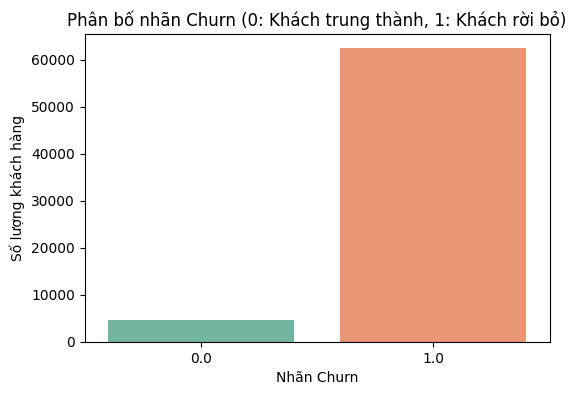

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_labeled, x='Churn', hue='Churn', palette='Set2', legend=False)
plt.title('Phân bố nhãn Churn (0: Khách trung thành, 1: Khách rời bỏ)')
plt.xlabel('Nhãn Churn')
plt.ylabel('Số lượng khách hàng')
plt.show()